In [7]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

# ==========================================
# STEP 1: The Schema-Enforced Load
# ==========================================
FOLDER_PATH = '../../data/raw/tracebench/AN_Net_slowDN_r_100ms_01FDN_30C_1to19B_0to120INT_15RT_5WT/'

# We explicitly define the exact columns based on the dataset documentation
EVENT_COLS = ['TaskID', 'TID', 'OpName', 'StartTime', 'EndTime', 'HostAddress', 'HostName', 'Agent', 'Description']
EDGE_COLS = ['TaskID', 'FatherTID', 'FatherStartTime', 'ChildTID']

# header=0 tells Pandas to ignore the broken headers in the file
# names=... forces Pandas to use our perfect headers
# index_col=False explicitly forbids Pandas from shifting the columns!
df_events = pd.read_csv(FOLDER_PATH + 'event.csv', header=0, names=EVENT_COLS, index_col=False)
df_edges = pd.read_csv(FOLDER_PATH + 'edge.csv', header=0, names=EDGE_COLS, index_col=False)

# Clean hidden spaces just to be perfectly safe
df_events['TaskID'] = df_events['TaskID'].astype(str).str.strip()
df_edges['TaskID'] = df_edges['TaskID'].astype(str).str.strip()

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_4684\1807882407.py:17: ParserWarning: Length of header or names does not match length of data. This leads to a loss of data with index_col=False.
  df_events = pd.read_csv(FOLDER_PATH + 'event.csv', header=0, names=EVENT_COLS, index_col=False)


In [10]:
# ==========================================
# STEP 2: Isolate the Task
# ==========================================
TARGET_TASK = '54A8BE4E5C6C7B6D'

# Because the columns are fixed, we can go back to clean, standard Pandas filtering!
events_filtered = df_events[df_events['TaskID'] == TARGET_TASK]
edges_filtered = df_edges[df_edges['TaskID'] == TARGET_TASK]

print(f"Isolated Task: {TARGET_TASK}")
print(f"Nodes found: {len(events_filtered)} | Edges found: {len(edges_filtered)}")

Isolated Task: 54A8BE4E5C6C7B6D
Nodes found: 199 | Edges found: 75


In [11]:
events_filtered

,TaskID,TID,OpName,StartTime,EndTime,HostAddress,HostName,Agent,Description
0,54A8BE4E5C6C7B6D,1B954355EC49214D,getFileInfo,3999566407785491,3999566408695489,10.107.100.57,namenode,Namenode,Success: return(OW[class=class org.apache.hado...
1,54A8BE4E5C6C7B6D,CC262623EEF32CA7,RPC:getFileInfo,807042962447849,807042973668509,10.107.100.120,client009,RPC Client,Success: return(OW[class=class org.apache.hado...
2,54A8BE4E5C6C7B6D,E893E7A663DF6470,getFileInfo,3999566424542846,3999566424779552,10.107.100.57,namenode,Namenode,Success: return(OW[class=class org.apache.hado...
3,54A8BE4E5C6C7B6D,CC262623EEF32CA7,RPC:getFileInfo,807042980292253,807042981943280,10.107.100.120,client009,RPC Client,Success: return(OW[class=class org.apache.hado...
8,54A8BE4E5C6C7B6D,7A8FB8B40352418B,getFileInfo,3999566483323622,3999566483521554,10.107.100.57,namenode,Namenode,Success: return(OW[class=class org.apache.hado...
...,...,...,...,...,...,...,...,...,...
1373,54A8BE4E5C6C7B6D,5E9A1590C50AA26E,OP: receive block,807101114025022,807101541421482,10.107.100.120,client009,DFSClient,Success: received a block
1374,54A8BE4E5C6C7B6D,CC262623EEF32CA7,checksumOk,807101541557190,807101541844729,10.107.100.120,client009,DFSClient,Success:
1375,54A8BE4E5C6C7B6D,3D6268E0D8D05921,fs -copyToLocal,807042957948552,807101542198853,10.107.100.120,client009,User,A user task
1376,54A8BE4E5C6C7B6D,56C74BEDD82A4F2B,verifiedByClient,811252300781440,811252305618570,10.107.100.30,datanode042,datanode,Success: blk_1369177574908557390_36817 verifie...


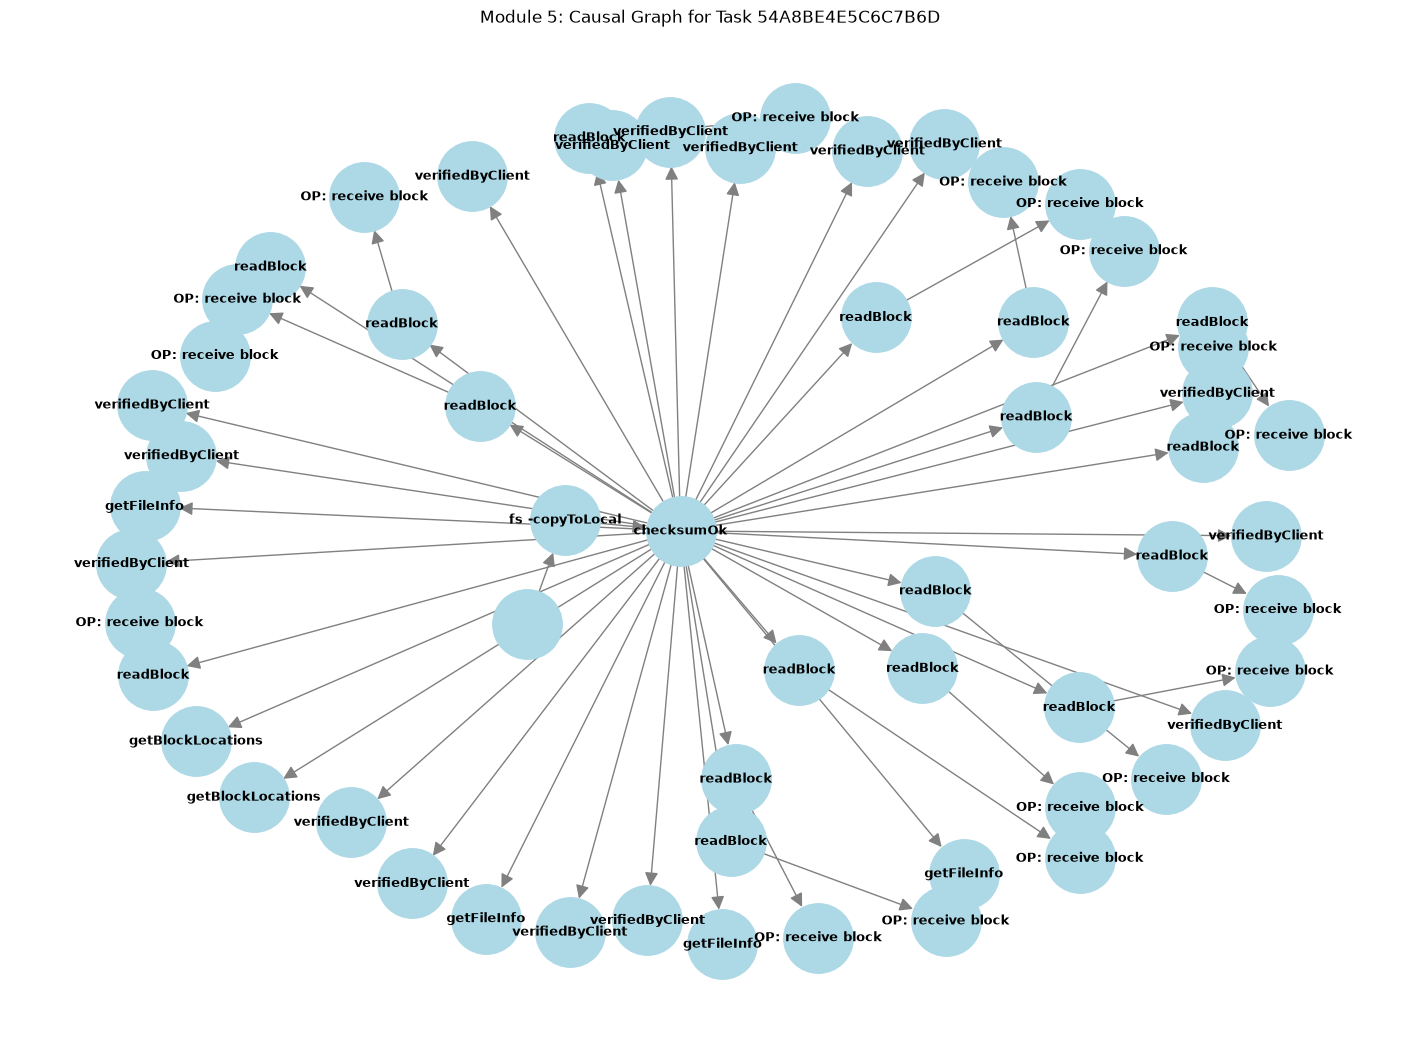

In [12]:
# ==========================================
# STEP 3: Build and Draw the DAG
# ==========================================
if len(events_filtered) == 0 or len(edges_filtered) == 0:
    print("❌ ERROR: Still 0? We have a bigger problem.")
else:
    G = nx.DiGraph()
    
    # Add Nodes
    for index, row in events_filtered.iterrows():
        G.add_node(str(row['TID']).strip(), label=str(row['OpName']).strip())
        
    # Add Edges
    for index, row in edges_filtered.iterrows():
        G.add_edge(str(row['FatherTID']).strip(), str(row['ChildTID']).strip())
        
    # Draw Graph
    plt.figure(figsize=(14, 10))
    pos = nx.spring_layout(G, k=0.8, iterations=100)
    nx.draw(G, pos, 
            labels=nx.get_node_attributes(G, 'label'), 
            with_labels=True, 
            node_color='lightblue', 
            edge_color='gray', 
            node_size=2500, 
            font_size=9, 
            font_weight='bold',
            arrows=True,
            arrowsize=20)
    
    plt.title(f"Module 5: Causal Graph for Task {TARGET_TASK}")
    plt.show()